<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Terrain analysis](https://github.com/Query-farm/vgi-terrain)

DEM visibility, viewsheds, slope and aspect from SQL.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-terrain/blob/main/notebooks/01_one_ray_is_not_a_viewshed.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-terrain/blob/main/notebooks/README.md)


## 01 · Clearing one ridge path does not clear the whole viewshed

How much does a taller observer change sampled terrain visibility? We will compare a fixed 2 m reference with a chosen observer height, evaluate every cell centre of a small DEM, and reconstruct one cross-ridge sightline in SQL. A receiver that becomes visible is one result among many; it does not establish visibility everywhere behind the ridge.

**All inputs are synthetic.** The pinned worker packages an 11 × 11 GeoTIFF with a 30 m ridge and constructed observer/receiver pairs. These are known-answer scientific fixtures, not a real survey or a dated observation. The actual raster, projection and visibility implementation runs through VGI. No live service, replacement dataset or credential is used.

### Choose the observer height above terrain

`SOURCE_HEIGHT_M` is a finite height from 0 to 150 in metres **above the DEM at the observer**, not an absolute altitude. Default **80 m** is compared with a fixed **2 m** reference; the separate experiment lowers it to **40 m**. Receivers remain 2 m above their local terrain.

The DEM uses **EPSG:32618**, X/Y order, 10 m horizontal cells and metre elevations. The worker samples each sightline at no more than 5 m spacing (half a pixel), uses nearest-cell elevations and applies effective-Earth-radius curvature with `k = 7/6`. These are sampled terrain results, not optical/radio propagation predictions. Restart Kernel → Run All after changing the parameter.

In [1]:
SOURCE_HEIGHT_M = 80.0  # metres above DEM; finite 0–150; experiment: 40.0

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.26":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.26"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the kernel, then run all cells.")

from vgi_notebooks import check_runtime  # noqa: E402

check_runtime()

In [3]:
import hashlib
import json
from pathlib import Path
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

theme()
session = connect(globals())

if (
    type(SOURCE_HEIGHT_M) not in (int, float)
    or not np.isfinite(SOURCE_HEIGHT_M)
    or not 0 <= SOURCE_HEIGHT_M <= 150
):
    raise ValueError("SOURCE_HEIGHT_M must be a finite number from 0 to 150 metres.")
SOURCE = "Source: bundled synthetic 10 m DEM · EPSG:32618 / metre elevations · vgi-terrain v0.1.0"
Path("artifacts").mkdir(exist_ok=True)

### Connect to the released worker

The literal Git-tag launcher starts published **v0.1.0** in an isolated Python 3.13 environment. The release owns its dependency constraints; no extra SDK override or local source checkout is needed. The notebook installs the shared base package; the local publication environment adds `[runner]`. First use needs package, Git and VGI extension downloads. The shared connection disables persistent SQL secrets and starts with an empty temporary secret directory.

### Form a bounded observer–receiver population

`demo://ridge.tif` is bundled synthetic package data, not a live acquisition. `dem_cells` loads all 121 cell centres; an inline `origin` row supplies the low observer and highlighted receiver geometry (the worker's `low` sample tower pair). We retain the low observer's position and receiver height, then replace only the selected observer height.

The two scenarios each include 121 cell-centre receivers plus one outside-DEM control: 244 rays in total. Materialize the worker calls once, then inspect local tables. A 5 m maximum step and at most 40 samples bound each ray. EPSG:32618 coordinates and elevations are in metres; nearest-cell sampling and curvature with k=7/6 are explicit.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'terrain' (TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-terrain@v0.1.0 vgi-terrain-worker');
CREATE TABLE cells AS
SELECT * FROM terrain.main.dem_cells('demo://ridge.tif', max_cells := 121);
CREATE TABLE origin AS SELECT 'low' pair_id,500015.0::DOUBLE source_x,4100055.0::DOUBLE source_y,
 500095.0::DOUBLE target_x,4100055.0::DOUBLE target_y,
 2.0::DOUBLE source_height_m,2.0::DOUBLE target_height_m;
CREATE TABLE scenarios(scenario VARCHAR,source_height_m DOUBLE);
INSERT INTO scenarios VALUES ('Reference',2.0),('Selected',{{SOURCE_HEIGHT_M}});
CREATE TABLE pairs AS
SELECT scenario||':'||cell_id::VARCHAR pair_id,scenario,'cell' target_type,cell_id,
 o.source_x,o.source_y,c.x target_x,c.y target_y,s.source_height_m,o.target_height_m
FROM scenarios s CROSS JOIN cells c CROSS JOIN origin o
UNION ALL
SELECT scenario||':outside',scenario,'outside',NULL::BIGINT,
 o.source_x,o.source_y,499995.0,o.source_y,s.source_height_m,o.target_height_m
FROM scenarios s CROSS JOIN origin o;
CREATE TABLE results AS
SELECT p.scenario,p.target_type,p.cell_id,p.source_height_m,v.*
FROM terrain.main.visibility((SELECT pair_id,source_x,source_y,target_x,target_y,
 source_height_m,target_height_m FROM pairs),dem := 'demo://ridge.tif',
 input_crs := 'EPSG:32618',step_m := 5.0,refraction_k := 1.1666666666666667,
 max_cells := 121,max_samples := 40) v JOIN pairs p USING(pair_id);

,Count


In [5]:
%%sql summary <<
SELECT scenario,max(source_height_m) source_height_m,
 count(*) FILTER(WHERE target_type='cell') grid_targets,
 count(*) FILTER(WHERE target_type='cell' AND visible) visible_cells,
 count(*) FILTER(WHERE target_type='cell' AND NOT visible) blocked_cells,
 count(*) FILTER(WHERE target_type='cell' AND visible IS NULL) unknown_cells,
 count(*) FILTER(WHERE target_type='outside' AND visible IS NULL) outside_unknown
FROM results GROUP BY scenario ORDER BY scenario;

### Map the receiver population, including what the map omits

Every coloured square represents the **status at its cell-centre receiver**, 2 m above the DEM. Colouring a whole square makes the grid legible; it does not claim visibility at every point within that square. The dashed outline marks the ridge column. The star is the observer and the circle is the cross-ridge receiver used below.

The outside control is reported separately because it lies beyond the mapped raster. `outside_dem` and `nodata` mean unknown visibility, not a blocked or clear ray. Do not turn NULL into false when reporting a visibility rate.

In [6]:
%%sql cells <<
SELECT * FROM cells ORDER BY cell_id;

In [7]:
%%sql views <<
SELECT r.scenario,r.cell_id,r.status,r.visible,c.x,c.y,c.elevation_m
FROM results r JOIN cells c USING(cell_id) WHERE target_type='cell' ORDER BY scenario,cell_id;

In [8]:
%%sql reference <<
SELECT pair_id,visible,distance_m,min_clearance_m,sample_count,status
FROM results WHERE scenario='Reference' ORDER BY pair_id;

,scenario,source_height_m,grid_targets,visible_cells,blocked_cells,unknown_cells,outside_unknown
0,Reference,2.0,121,55,66,0,1
1,Selected,80.0,121,99,22,0,1


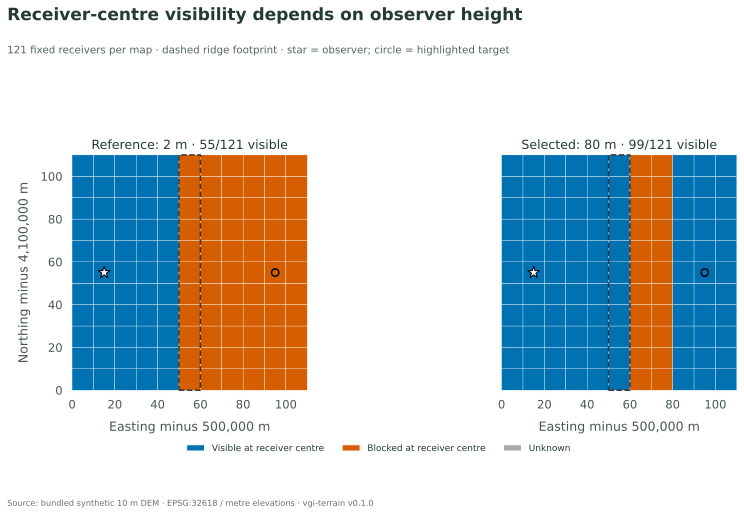

At **80 m**, **99/121 receiver centres** are visible and **22 are blocked**; the fixed 2 m observer sees **55/121**. Grid unknowns are **0**. Each scenario also has **1 outside-DEM control** with NULL visibility. The unchanged DEM/reference fingerprint is `7cfbb9d2a56d3c0515aa7d6d7267c02d22c16f5e4228bcc3c4e5dd8bdcb6d19d`.

In [9]:
display(summary)
fingerprint = hashlib.sha256(
    (cells.to_json(orient="records") + reference.to_json(orient="records")).encode()
).hexdigest()
fig, axes = plt.subplots(1, 2, figsize=(12, 7.6), sharex=True, sharey=True)
cmap = ListedColormap(["#d55e00", "#0072b2", "#aaaaaa"])
norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], cmap.N)
for ax, scenario in zip(axes, ["Reference", "Selected"], strict=True):
    subset = views[views.scenario.eq(scenario)].copy()
    subset["value"] = subset.status.map({"blocked": 0, "visible": 1}).fillna(2)
    grid = subset.pivot(index="y", columns="x", values="value").sort_index()
    ax.pcolormesh(
        np.arange(0, 111, 10),
        np.arange(0, 111, 10),
        grid.values,
        cmap=cmap,
        norm=norm,
        edgecolors="white",
        linewidth=0.3,
    )
    ax.plot(
        [50, 60, 60, 50, 50], [0, 0, 110, 110, 0], color="#333333", linestyle="--", linewidth=1.5
    )
    ax.scatter(15, 55, marker="*", s=150, c="white", edgecolor="black", zorder=5)
    ax.scatter(
        95, 55, marker="o", s=55, facecolors="none", edgecolor="black", linewidth=1.5, zorder=5
    )
    row = summary[summary.scenario.eq(scenario)].iloc[0]
    ax.set(
        title=f"{scenario}: {row.source_height_m:g} m · {row.visible_cells}/{row.grid_targets} visible",
        xlabel="Easting minus 500,000 m",
        aspect="equal",
        xticks=[0, 20, 40, 60, 80, 100],
    )
axes[0].set_ylabel("Northing minus 4,100,000 m")
fig.legend(
    handles=[
        Patch(facecolor="#0072b2", label="Visible at receiver centre"),
        Patch(facecolor="#d55e00", label="Blocked at receiver centre"),
        Patch(facecolor="#aaaaaa", label="Unknown"),
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, 0.14),
    ncol=3,
    fontsize=9,
)

fig.subplots_adjust(left=0.08, right=0.98, bottom=0.22, top=0.82, wspace=0.20)
finish(
    fig,
    "Receiver-centre visibility depends on observer height",
    "121 fixed receivers per map · dashed ridge footprint · star = observer; circle = highlighted target",
    SOURCE,
    name=f"viewshed-{SOURCE_HEIGHT_M:g}",
)
ref = summary.iloc[0]
sel = summary.iloc[1]
prose(
    f"At **{SOURCE_HEIGHT_M:g} m**, **{sel.visible_cells}/{sel.grid_targets} receiver centres** are visible and **{sel.blocked_cells} are blocked**; the fixed 2 m observer sees **{ref.visible_cells}/{ref.grid_targets}**. Grid unknowns are **{sel.unknown_cells}**. Each scenario also has **{sel.outside_unknown} outside-DEM control** with NULL visibility. The unchanged DEM/reference fingerprint is `{fingerprint}`."
)

### Reconstruct one ray rather than infer it from the map

The highlighted route runs 80 m east from the observer to the original demo receiver. SQL rebuilds its uniformly spaced samples, selects the containing DEM cell, adds the endpoint heights to terrain elevation, and subtracts the same curvature term. This is an independent SQL expression of the worker's documented rule, checked against its returned minimum clearance.

The minimum is over **interior samples only**. Visibility accepts clearance ≥ −10⁻⁹ m for numerical tolerance. A ray missing any required DEM sample is unknown; the reconstruction below intentionally uses the fully covered highlighted route. Sampling at half a pixel does not resolve obstacles absent from the DEM.

In [10]:
%%sql
CREATE TABLE route_results AS
SELECT r.*,p.source_x,p.source_y,p.target_x,p.target_y,p.target_height_m
FROM results r JOIN pairs p USING(pair_id) CROSS JOIN origin o
WHERE p.target_type='cell' AND p.target_x=o.target_x AND p.target_y=o.target_y;
CREATE TABLE ray_samples AS
WITH positions AS (
 SELECT r.*,i,i::DOUBLE/(sample_count-1) t,
 source_x+i::DOUBLE/(sample_count-1)*(target_x-source_x) sample_x,
 source_y+i::DOUBLE/(sample_count-1)*(target_y-source_y) sample_y
 FROM route_results r,range(sample_count) AS sample(i)),
elevations AS (
 SELECT p.*,c.elevation_m terrain_m,
 s.elevation_m+source_height_m source_z,
 e.elevation_m+target_height_m target_z
 FROM positions p
 JOIN cells c ON c.cell_id=floor((4100110-sample_y)/10)::BIGINT*11+floor((sample_x-500000)/10)::BIGINT
 JOIN cells s ON s.x=p.source_x AND s.y=p.source_y
 JOIN cells e ON e.x=p.target_x AND e.y=p.target_y)
SELECT *,t*distance_m distance_along_m,
 source_z+t*(target_z-source_z) line_z,
 t*(1-t)*pow(distance_m,2)/(2*(7.0/6.0)*6371008.8) curvature_m,
 source_z+t*(target_z-source_z)-terrain_m
  -t*(1-t)*pow(distance_m,2)/(2*(7.0/6.0)*6371008.8) reconstructed_clearance_m
FROM elevations;

,Count


In [11]:
%%sql routes <<
SELECT r.scenario,r.source_height_m,r.visible,r.status,r.distance_m,r.sample_count,
 r.min_clearance_m,min(s.reconstructed_clearance_m) reconstructed_min_m
FROM route_results r JOIN ray_samples s USING(pair_id)
WHERE s.i>0 AND s.i<s.sample_count-1
GROUP BY ALL ORDER BY scenario;

In [12]:
%%sql checks <<
SELECT
 (SELECT abs(count(*)-121)+count(*) FILTER(WHERE elevation_m IS NULL OR dem_crs<>'EPSG:32618') FROM cells) dem_population,
 (SELECT abs(count(*)-244) FROM results) result_population,
 (SELECT count(*)-count(DISTINCT pair_id) FROM results) duplicate_pairs,
 count(*) FILTER(WHERE (status='visible' AND visible IS DISTINCT FROM TRUE)
  OR (status='blocked' AND visible IS DISTINCT FROM FALSE)
  OR (status IN ('outside_dem','nodata') AND visible IS NOT NULL)) status_mismatches,
 count(*) FILTER(WHERE target_type='outside' AND (status<>'outside_dem' OR visible IS NOT NULL
  OR min_clearance_m IS NOT NULL OR sightline_wkb IS NOT NULL)) unknown_mismatches,
 count(*) FILTER(WHERE status IN ('visible','blocked') AND (min_clearance_m IS NULL OR sightline_wkb IS NULL)) missing_known_geometry,
 count(*) FILTER(WHERE visible IS NOT NULL AND visible<>(min_clearance_m>=-1e-9)) clearance_flag_mismatches,
 count(*) FILTER(WHERE sample_count<>greatest(3,ceil(distance_m/5)+1) OR sample_count>40) sample_count_mismatches,
 (SELECT count(*) FROM results r JOIN pairs p USING(pair_id)
  WHERE abs(r.distance_m-sqrt(pow(target_x-source_x,2)+pow(target_y-source_y,2)))>1e-9) distance_mismatches,
 (SELECT count(*) FROM route_results r JOIN (
  SELECT pair_id,min(reconstructed_clearance_m) reconstructed_min_m FROM ray_samples
  WHERE i>0 AND i<sample_count-1 GROUP BY pair_id) s USING(pair_id)
  WHERE abs(r.min_clearance_m-s.reconstructed_min_m)>1e-10) reconstructed_min_mismatches
FROM results;

In [13]:
%%sql profile <<
SELECT scenario,i,distance_along_m,terrain_m,line_z,curvature_m,reconstructed_clearance_m
FROM ray_samples ORDER BY scenario,i;

,scenario,source_height_m,visible,status,distance_m,sample_count,min_clearance_m,reconstructed_min_m
0,Reference,2.0,False,blocked,80.0,17,-28.000108,-28.000108
1,Selected,80.0,True,visible,80.0,17,6.874975,6.874975


,dem_population,result_population,duplicate_pairs,status_mismatches,unknown_mismatches,missing_known_geometry,clearance_flag_mismatches,sample_count_mismatches,distance_mismatches,reconstructed_min_mismatches
0,0,0,0,0,0,0,0,0,0,0


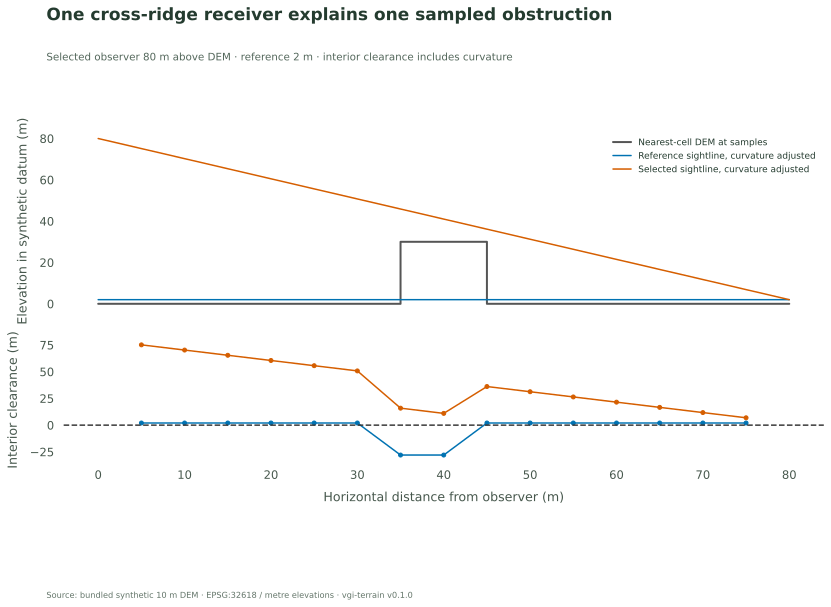

The highlighted receiver is **visible** at **80 m** observer height. Its **17 samples** span **80 m**, with minimum interior clearance **6.875 m**. The SQL reconstruction agrees within 10⁻¹⁰ m. Ten SQL checks plus population controls pass. This explains this ray under the stated sampling model; it does not establish continuous visibility or a radio link budget.

In [14]:
display(routes)
display(checks)
assert checks.iloc[0].eq(0).all()
assert len(routes) == 2 and summary.grid_targets.eq(121).all()
assert summary.outside_unknown.eq(1).all()
if SOURCE_HEIGHT_M >= 2:
    assert sel.visible_cells >= ref.visible_cells
fig, (a, b) = plt.subplots(
    2, 1, figsize=(12, 9), sharex=True, gridspec_kw={"height_ratios": [1.5, 1]}
)
terrain = profile[profile.scenario.eq("Reference")]
a.step(
    terrain.distance_along_m,
    terrain.terrain_m,
    where="post",
    color="#555555",
    linewidth=2,
    label="Nearest-cell DEM at samples",
)
for scenario, color in [("Reference", "#0072b2"), ("Selected", "#d55e00")]:
    data = profile[profile.scenario.eq(scenario)]
    a.plot(
        data.distance_along_m,
        data.line_z - data.curvature_m,
        color=color,
        label=f"{scenario} sightline, curvature adjusted",
    )
    interior = data[(data.i > 0) & (data.i < data.i.max())]
    b.plot(
        interior.distance_along_m,
        interior.reconstructed_clearance_m,
        marker="o",
        markersize=4,
        color=color,
        label=scenario,
    )
a.set(ylabel="Elevation in synthetic datum (m)")
a.legend(fontsize=9, loc="upper right")
b.axhline(0, color="#333333", linestyle="--")
b.set(xlabel="Horizontal distance from observer (m)", ylabel="Interior clearance (m)")

fig.subplots_adjust(left=0.10, right=0.98, bottom=0.14, top=0.90, hspace=0.18)
finish(
    fig,
    "One cross-ridge receiver explains one sampled obstruction",
    f"Selected observer {SOURCE_HEIGHT_M:g} m above DEM · reference 2 m · interior clearance includes curvature",
    SOURCE,
    name=f"ray-clearance-{SOURCE_HEIGHT_M:g}",
)
r = routes[routes.scenario.eq("Selected")].iloc[0]
prose(
    f"The highlighted receiver is **{r.status}** at **{SOURCE_HEIGHT_M:g} m** observer height. Its **{r.sample_count} samples** span **{r.distance_m:g} m**, with minimum interior clearance **{r.min_clearance_m:.3f} m**. The SQL reconstruction agrees within 10⁻¹⁰ m. Ten SQL checks plus population controls pass. This explains this ray under the stated sampling model; it does not establish continuous visibility or a radio link budget."
)

### Preserve unknowns and the sampling model

A higher observer can reveal additional receiver centres without clearing the whole grid. The map uses a fixed 121-cell population, so changes are comparable. The separate 40 m experiment keeps the DEM, low-observer reference, target heights and sampling controls fixed; compare both the map count and highlighted ray, not just one headline percentage.

A real DEM needs known horizontal and vertical units, valid coverage and sufficient terrain detail. This worker rejects declared non-metre elevations and applies raster scale/offset. Buildings or vegetation absent from the elevation surface, subpixel obstructions, Fresnel zones, atmospheric variability and sensor error are outside this calculation. Missing terrain remains unknown. A 5 m sampling step on a 10 m raster adds samples, not new terrain information.

The source/readme documents resource caps and status semantics. For another region, supply a complete bounded DEM covering every ray, retain the input version and CRS, and report visible, blocked and unknown populations separately.

In [15]:
audit = {
    "source_height_m": SOURCE_HEIGHT_M,
    "control_fingerprint": fingerprint,
    "cells": json.loads(cells.to_json(orient="records")),
    "reference": json.loads(reference.to_json(orient="records")),
    "summary": json.loads(summary.to_json(orient="records")),
    "routes": json.loads(routes.to_json(orient="records")),
    "checks": checks.iloc[0].to_dict(),
}
Path("artifacts/analysis-audit.json").write_text(json.dumps(audit, indent=2) + "\n")
session.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-terrain](https://github.com/Query-farm/vgi-terrain)
